Specificity of this file:
We will train on quotes, test on trades, for both prices and implied vol.
Rolling window to post match trade.

In [46]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import polars as pl
import pytz

## DATA LOADING

In [2]:
project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

from quantdata.massive.client import MassiveClient


def test():

    ticker = "SPY"
    d = date(2024, 1, 3)
    client = MassiveClient()
    option_ticker = "O:SPY240105P00470000"

    def package(ticker, verbose=Context.all):

        with verbose.write_t(
            f"Fetching OCV, trades, quotes for {ticker} on {fmt_date(d)}... ", end=""
        ) as tme:
            ocv = client.fetch_day_summary(ticker, d, adjusted=True)
            verbose.write(f"done: found {fmt_dict(ocv)}. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching trades for {ticker} on {fmt_date(d)}... ", end="") as tme:
            trades = client.fetch_trades(ticker, d)
            verbose.write(f"done: found {len(trades)} trades. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching quotes for {ticker} on {fmt_date(d)}... ", end="") as tme:
            quotes = client.fetch_quotes(ticker, d)
            verbose.write(f"done: found {len(quotes)} quotes. This took {tme}.", head=False)

        return ocv, trades, quotes

    package(ticker)
    ocv, trades, quotes = package(option_ticker)

    display(ocv)
    display(trades.head())
    display(quotes.head())


test()

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


00: Fetching OCV, trades, quotes for SPY on 2024-01-03... done: found open: 470.43, close: 468.79, volume: 103577866.0, high: 471.19, low: 468.17, afterHours: 469.35, preMarket: 472.07 and adjusted: True. This took 0.462ms.
00: Fetching trades for SPY on 2024-01-03... done: found 656589 trades. This took 8.22ms.
00: Fetching quotes for SPY on 2024-01-03... done: found 4927896 quotes. This took 0.049s.
00: Fetching OCV, trades, quotes for O:SPY240105P00470000 on 2024-01-03... done: found open: 1.67, close: 2.38, volume: 69357.0, high: 2.71, low: 1.25, afterHours: 2.43, preMarket: 1.67 and adjusted: True. This took 4.64ms.
00: Fetching trades for O:SPY240105P00470000 on 2024-01-03... done: found 8895 trades. This took 2.09ms.
00: Fetching quotes for O:SPY240105P00470000 on 2024-01-03... done: found 85145 quotes. This took 4.07ms.


{'open': 1.67,
 'close': 2.38,
 'volume': 69357.0,
 'high': 2.71,
 'low': 1.25,
 'afterHours': 2.43,
 'preMarket': 1.67,
 'adjusted': True}

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.424 EST,1.67,1.0,256
2024-01-03 09:30:00.472 EST,1.69,4.0,64
2024-01-03 09:30:00.576 EST,1.7,10.0,64
2024-01-03 09:30:00.617 EST,1.71,1.0,576
2024-01-03 09:30:01.480 EST,1.71,1.0,256


ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.217322240 EST,1.72,46.0,1.74,46.0
2024-01-03 09:30:00.383298048 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.400694528 EST,1.69,2.0,1.8,36.0
2024-01-03 09:30:00.419033088 EST,1.67,80.0,1.8,36.0


In [3]:
option_ticker = "O:SPY240105P00470000"

In [4]:
client = MassiveClient()
df_quotes = client.fetch_quotes(option_ticker, date(2024, 1, 3))
df_quotes

ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.217322240 EST,1.72,46.0,1.74,46.0
2024-01-03 09:30:00.383298048 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.400694528 EST,1.69,2.0,1.8,36.0
2024-01-03 09:30:00.419033088 EST,1.67,80.0,1.8,36.0
…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,2.35,38.0,2.37,123.0
2024-01-03 16:14:42.450262016 EST,2.35,41.0,2.37,93.0
2024-01-03 16:14:54.333178624 EST,2.36,70.0,2.38,30.0


In [5]:
df_trades = client.fetch_trades(option_ticker, date(2024, 1, 3))

In [6]:
df_trades

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.424 EST,1.67,1.0,256
2024-01-03 09:30:00.472 EST,1.69,4.0,64
2024-01-03 09:30:00.576 EST,1.7,10.0,64
2024-01-03 09:30:00.617 EST,1.71,1.0,576
2024-01-03 09:30:01.480 EST,1.71,1.0,256
…,…,…,…
2024-01-03 16:11:20.628 EST,2.37,72.0,2624
2024-01-03 16:11:20.628 EST,2.37,72.0,2624
2024-01-03 16:12:51.108 EST,2.38,1.0,2624


In [7]:
df_trades.head()

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.424 EST,1.67,1.0,256
2024-01-03 09:30:00.472 EST,1.69,4.0,64
2024-01-03 09:30:00.576 EST,1.7,10.0,64
2024-01-03 09:30:00.617 EST,1.71,1.0,576
2024-01-03 09:30:01.480 EST,1.71,1.0,256


In [8]:
df_spy = client.fetch_trades("SPY", date(2024, 1, 3))
df_spy.head()

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 04:00:00.023728896 EST,472.04,4.0,73728
2024-01-03 04:00:00.033502208 EST,472.43,16.0,73728
2024-01-03 04:00:00.035570944 EST,472.36,1.0,73728
2024-01-03 04:00:00.035577088 EST,472.31,4.0,73728
2024-01-03 04:00:00.370607616 EST,472.16,2.0,73728


In [9]:
from quantdata.massive.trade_conds import NORMAL_TRADE_EXCLUDE_FLAGS


def filter_df(df, col="trade_code"):
    return df.filter((pl.col(col) & int(NORMAL_TRADE_EXCLUDE_FLAGS)) == 0)

In [10]:
df_trades = filter_df(df_trades)
df_spy = filter_df(df_spy)

# Merging with time Lag

In [11]:
quotes_for_join = df_quotes.rename({"ts_ns": "quote_ts_ns"})

df_trade_spread = df_trades.join_asof(
    quotes_for_join.sort("quote_ts_ns"),
    left_on="ts_ns",
    right_on="quote_ts_ns",
    strategy="backward",
)

df_trade_spread = df_trade_spread.with_columns(
    (pl.col("ts_ns") - pl.col("quote_ts_ns")).dt.total_nanoseconds().alias("quote_age")
)

In [12]:
df_trade_spread

ts_ns,price,size,trade_code,quote_ts_ns,bid_price,bid_size,ask_price,ask_size,quote_age
"datetime[ns, America/New_York]",f64,f64,u32,"datetime[ns, America/New_York]",f64,f64,f64,f64,i64
2024-01-03 09:30:00.424 EST,1.67,1.0,256,2024-01-03 09:30:00.419033088 EST,1.67,80.0,1.8,36.0,4966912
2024-01-03 09:30:00.472 EST,1.69,4.0,64,2024-01-03 09:30:00.470255104 EST,1.64,80.0,1.8,36.0,1744896
2024-01-03 09:30:00.576 EST,1.7,10.0,64,2024-01-03 09:30:00.573615872 EST,1.7,54.0,1.72,40.0,2384128
2024-01-03 09:30:00.617 EST,1.71,1.0,576,2024-01-03 09:30:00.573615872 EST,1.7,54.0,1.72,40.0,43384128
2024-01-03 09:30:01.480 EST,1.71,1.0,256,2024-01-03 09:30:01.019511808 EST,1.7,54.0,1.72,40.0,460488192
…,…,…,…,…,…,…,…,…,…
2024-01-03 16:11:20.628 EST,2.37,72.0,2624,2024-01-03 16:11:20.520283392 EST,2.39,27.0,2.4,37.0,107716608
2024-01-03 16:11:20.628 EST,2.37,72.0,2624,2024-01-03 16:11:20.520283392 EST,2.39,27.0,2.4,37.0,107716608
2024-01-03 16:12:51.108 EST,2.38,1.0,2624,2024-01-03 16:12:42.623446272 EST,2.36,85.0,2.39,110.0,8484553728


In [13]:
(df_trade_spread.select("bid_size") == 0).sum()

bid_size
u32
0


In [20]:
TRADE_LAG_NS = 250_000_000  # 250ms in nanoseconds


def match_trade_to_closest_quote(df_trades: pl.DataFrame, df_quotes: pl.DataFrame) -> pl.DataFrame:
    """
    For each trade at time t, use the last quote in [t, t+250ms].
    Falls back to the last quote before t if no forward quote exists in the window.
    """
    quotes_sorted = df_quotes.sort("ts_ns").select(
        ["ts_ns", "bid_price", "ask_price", "bid_size", "ask_size"]
    )

    # --- forward-window match: last quote in [t, t+250ms] ---
    # Backward join on (t + 250ms) gives the last quote <= t+250ms;
    # reject it if it landed before t (i.e. outside the window).
    forward = (
        df_trades.with_columns(
            (pl.col("ts_ns") + pl.duration(nanoseconds=TRADE_LAG_NS)).alias("ts_ns_window_end")
        )
        .join_asof(
            quotes_sorted.rename({"ts_ns": "quote_ts_fwd"}),
            left_on="ts_ns_window_end",
            right_on="quote_ts_fwd",
            strategy="backward",
        )
        .drop("ts_ns_window_end")
        .with_columns(
            pl.when(pl.col("quote_ts_fwd") >= pl.col("ts_ns"))
            .then((pl.col("quote_ts_fwd") - pl.col("ts_ns")).dt.total_nanoseconds())
            .otherwise(None)
            .alias("fwd_lag_ns")
        )
    )

    # --- backward match: last quote at or before t (fallback only) ---
    backward = df_trades.join_asof(
        quotes_sorted.rename({"ts_ns": "quote_ts_bwd"}),
        left_on="ts_ns",
        right_on="quote_ts_bwd",
        strategy="backward",
    ).with_columns(
        (pl.col("ts_ns") - pl.col("quote_ts_bwd")).dt.total_nanoseconds().alias("bwd_lag_ns")
    )

    # --- prefer last quote in window; fall back to backward if window is empty ---
    combined = forward.with_columns(
        [
            backward["bwd_lag_ns"].alias("bwd_lag_ns"),
            backward["bid_price"].alias("bid_price_bwd"),
            backward["ask_price"].alias("ask_price_bwd"),
            backward["bid_size"].alias("bid_size_bwd"),
            backward["ask_size"].alias("ask_size_bwd"),
        ]
    ).with_columns(
        [
            pl.when(pl.col("fwd_lag_ns").is_not_null())
            .then(pl.col("bid_price"))
            .otherwise(pl.col("bid_price_bwd"))
            .alias("best_bid"),
            pl.when(pl.col("fwd_lag_ns").is_not_null())
            .then(pl.col("ask_price"))
            .otherwise(pl.col("ask_price_bwd"))
            .alias("best_ask"),
            pl.when(pl.col("fwd_lag_ns").is_not_null())
            .then(pl.col("bid_size"))
            .otherwise(pl.col("bid_size_bwd"))
            .alias("best_bid_size"),
            pl.when(pl.col("fwd_lag_ns").is_not_null())
            .then(pl.col("ask_size"))
            .otherwise(pl.col("ask_size_bwd"))
            .alias("best_ask_size"),
            pl.when(pl.col("fwd_lag_ns").is_not_null())
            .then(pl.col("fwd_lag_ns"))
            .otherwise(-pl.col("bwd_lag_ns"))
            .alias("matched_lag_ns"),
        ]
    )

    return combined

In [21]:
df_combined = match_trade_to_closest_quote(df_trades=df_trades, df_quotes=df_quotes)

In [22]:
df_combined

ts_ns,price,size,trade_code,quote_ts_fwd,bid_price,ask_price,bid_size,ask_size,fwd_lag_ns,bwd_lag_ns,bid_price_bwd,ask_price_bwd,bid_size_bwd,ask_size_bwd,best_bid,best_ask,best_bid_size,best_ask_size,matched_lag_ns
"datetime[ns, America/New_York]",f64,f64,u32,"datetime[ns, America/New_York]",f64,f64,f64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,i64
2024-01-03 09:30:00.424 EST,1.67,1.0,256,2024-01-03 09:30:00.573615872 EST,1.7,1.72,54.0,40.0,149615872,4966912,1.67,1.8,80.0,36.0,1.7,1.72,54.0,40.0,149615872
2024-01-03 09:30:00.472 EST,1.69,4.0,64,2024-01-03 09:30:00.573615872 EST,1.7,1.72,54.0,40.0,101615872,1744896,1.64,1.8,80.0,36.0,1.7,1.72,54.0,40.0,101615872
2024-01-03 09:30:00.576 EST,1.7,10.0,64,2024-01-03 09:30:00.789349376 EST,1.7,1.72,40.0,40.0,213349376,2384128,1.7,1.72,54.0,40.0,1.7,1.72,40.0,40.0,213349376
2024-01-03 09:30:00.617 EST,1.71,1.0,576,2024-01-03 09:30:00.789349376 EST,1.7,1.72,40.0,40.0,172349376,43384128,1.7,1.72,54.0,40.0,1.7,1.72,40.0,40.0,172349376
2024-01-03 09:30:01.480 EST,1.71,1.0,256,2024-01-03 09:30:01.019511808 EST,1.7,1.72,54.0,40.0,null,460488192,1.7,1.72,54.0,40.0,1.7,1.72,54.0,40.0,-460488192
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:11:20.628 EST,2.37,72.0,2624,2024-01-03 16:11:20.520283392 EST,2.39,2.4,27.0,37.0,null,107716608,2.39,2.4,27.0,37.0,2.39,2.4,27.0,37.0,-107716608
2024-01-03 16:11:20.628 EST,2.37,72.0,2624,2024-01-03 16:11:20.520283392 EST,2.39,2.4,27.0,37.0,null,107716608,2.39,2.4,27.0,37.0,2.39,2.4,27.0,37.0,-107716608
2024-01-03 16:12:51.108 EST,2.38,1.0,2624,2024-01-03 16:12:42.623446272 EST,2.36,2.39,85.0,110.0,null,8484553728,2.36,2.39,85.0,110.0,2.36,2.39,85.0,110.0,-8484553728


In [23]:
df_combined.select(pl.col("fwd_lag_ns").is_null()).sum()

fwd_lag_ns
u32
3858


In [24]:
# ── QUOTES ───────────────────────────────────────────────────────────────────
quote_events = df_quotes.with_columns(
    [
        pl.lit("quote").alias("event_type"),
        (
            (pl.col("ask_size") * pl.col("bid_price") + pl.col("bid_size") * pl.col("ask_price"))
            / (pl.col("bid_size") + pl.col("ask_size"))
        ).alias("observed_price"),
        (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
        pl.lit(0).cast(pl.Int64).alias("matched_lag_ns"),
    ]
)

# ── TRADES ───────────────────────────────────────────────────────────────────
df_trade_spread = match_trade_to_closest_quote(df_trades, df_quotes)

trade_events = df_trade_spread.with_columns(
    [
        pl.lit("trade").alias("event_type"),
        pl.col("price").alias("observed_price"),
        (pl.col("best_ask") - pl.col("best_bid")).alias("spread"),
        pl.col("best_bid").alias("bid_price"),
        pl.col("best_ask").alias("ask_price"),
        pl.col("best_bid_size").alias("bid_size"),
        pl.col("best_ask_size").alias("ask_size"),
    ]
)

# ── COMBINE ──────────────────────────────────────────────────────────────────
SHARED_COLS = [
    "ts_ns",
    "event_type",
    "observed_price",
    "spread",
    "bid_price",
    "ask_price",
    "bid_size",
    "ask_size",
    "matched_lag_ns",
]

df_events = pl.concat(
    [
        quote_events.select(SHARED_COLS),
        trade_events.select(SHARED_COLS),
    ]
).sort("ts_ns")

In [25]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,matched_lag_ns
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,i64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0
…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0


In [26]:
df_events = df_events.drop_nans()

In [27]:
# ── CONFIG ──────────────────────────────────────────────────────────────────
ONE_SIDED_R_MULTIPLIER = 10.0  # inflate variance for one-sided quotes
TRADE_R_DIVISOR = 4.0  # trades are more trusted than quotes
STALE_QUOTE_THRESHOLD = 60_000  # ms — mark quote as stale beyond this
TRADE_LAG_NS = 250_000_000  # 250ms in nanoseconds


# ── 1. PROCESS QUOTES ───────────────────────────────────────────────────────
def process_quotes(df_quotes: pl.DataFrame) -> pl.DataFrame:
    df = (
        df_quotes.with_columns(
            [
                pl.when(pl.col("bid_price") <= 0)
                .then(None)
                .otherwise(pl.col("bid_price"))
                .alias("bid_price"),
                pl.when(pl.col("ask_price") <= 0)
                .then(None)
                .otherwise(pl.col("ask_price"))
                .alias("ask_price"),
                pl.when(pl.col("bid_size") <= 0)
                .then(None)
                .otherwise(pl.col("bid_size"))
                .alias("bid_size"),
                pl.when(pl.col("ask_size") <= 0)
                .then(None)
                .otherwise(pl.col("ask_size"))
                .alias("ask_size"),
            ]
        )
        .with_columns(
            pl.when(pl.col("bid_price").is_not_null() & pl.col("ask_price").is_not_null())
            .then(pl.lit("two_sided"))
            .when(pl.col("bid_price").is_not_null())
            .then(pl.lit("bid_only"))
            .when(pl.col("ask_price").is_not_null())
            .then(pl.lit("ask_only"))
            .otherwise(pl.lit("empty"))
            .alias("quote_side")
        )
        .filter(pl.col("quote_side") != "empty")
        .with_columns(
            [
                pl.when(pl.col("quote_side") == "two_sided")
                .then(
                    (
                        pl.col("ask_size") * pl.col("bid_price")
                        + pl.col("bid_size") * pl.col("ask_price")
                    )
                    / (pl.col("ask_size") + pl.col("bid_size"))
                )
                .when(pl.col("quote_side") == "bid_only")
                .then(pl.col("bid_price"))
                .otherwise(pl.col("ask_price"))
                .alias("observed_price"),
                pl.when(pl.col("quote_side") == "two_sided")
                .then(pl.col("ask_price") - pl.col("bid_price"))
                .otherwise(None)
                .alias("spread"),
            ]
        )
        .with_columns(pl.col("spread").fill_null(strategy="forward").alias("spread_filled"))
        .with_columns(
            [
                pl.when(pl.col("quote_side") == "two_sided")
                .then(
                    (pl.col("spread") / 2) ** 2
                    / (1 + (pl.col("bid_size") + pl.col("ask_size")).log1p())
                )
                .otherwise((pl.col("spread_filled") / 2) ** 2 * ONE_SIDED_R_MULTIPLIER)
                .alias("R"),
                pl.lit("quote").alias("event_type"),
                pl.lit(0).cast(pl.Int64).alias("matched_lag_ns"),  # no lag for quotes
            ]
        )
        .select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
                "R",
                "matched_lag_ns",
            ]
        )
    )
    return df


# ── 2. PROCESS TRADES ───────────────────────────────────────────────────────
def process_trades(df_trades: pl.DataFrame, df_quotes: pl.DataFrame) -> pl.DataFrame:
    """
    Matches each trade to the closest forward quote within 250ms (Option 2).
    Falls back to the last prior quote if no forward quote exists in the window.
    Lag is carried as matched_lag_ns for later diagnostics — not used in R.
    """
    df_matched = match_trade_to_closest_quote(df_trades, df_quotes)

    df = (
        df_matched.with_columns(
            [
                pl.lit("trade").alias("event_type"),
                pl.col("price").alias("observed_price"),
                (pl.col("best_ask") - pl.col("best_bid")).alias("spread"),
                pl.col("best_bid").alias("bid_price"),
                pl.col("best_ask").alias("ask_price"),
                pl.col("best_bid_size").alias("bid_size"),
                pl.col("best_ask_size").alias("ask_size"),
            ]
        )
        .with_columns(
            pl.when(pl.col("spread").is_not_null())
            .then((pl.col("spread") / 2) ** 2 / TRADE_R_DIVISOR)
            .otherwise((pl.col("observed_price") * 0.01) ** 2)
            .alias("R")
        )
        .select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
                "R",
                "matched_lag_ns",
            ]
        )
    )
    return df


# ── 3. MERGE INTO EVENT STREAM ───────────────────────────────────────────────
def build_event_stream(df_quotes: pl.DataFrame, df_trades: pl.DataFrame) -> pl.DataFrame:
    df_q = process_quotes(df_quotes)
    df_t = process_trades(df_trades, df_quotes)  # pass raw quotes, not processed

    df_events = (
        pl.concat([df_q, df_t], how="diagonal")
        .sort("ts_ns")
        .with_columns(pl.col("spread").fill_null(strategy="forward"))
    )
    return df_events


# ── 4. KALMAN FILTER ─────────────────────────────────────────────────────────
# unchanged
def kalman_filter(df_events: pl.DataFrame, Q: float = 0.01) -> pl.DataFrame:
    obs_prices = df_events["observed_price"].to_numpy()
    Rs = df_events["R"].to_numpy()
    n = len(obs_prices)

    x_est = np.empty(n)
    P_est = np.empty(n)

    x_est[0] = obs_prices[0]
    P_est[0] = Rs[0]

    for t in range(1, n):
        x_pred = x_est[t - 1]
        P_pred = P_est[t - 1] + Q
        R_t = Rs[t]
        K = P_pred / (P_pred + R_t)
        x_est[t] = x_pred + K * (obs_prices[t] - x_pred)
        P_est[t] = (1 - K) * P_pred

    return df_events.with_columns(
        [
            pl.Series("kalman_price", x_est),
            pl.Series("kalman_var", P_est),
        ]
    )


# ── USAGE ────────────────────────────────────────────────────────────────────
# df_events  = build_event_stream(df_quotes, df_trades)
# df_results = kalman_filter(df_events, Q=0.01)

In [28]:
df_events = build_event_stream(df_quotes, df_trades)

In [29]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,0
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,0
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,0
…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,0
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,0
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,0


In [30]:
df_events.select(pl.col("R").is_null().sum())

R
u32
0


In [31]:
df_events = df_events.filter(pl.col("R").is_not_null())

In [32]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,0
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,0
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,0
…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,0
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,0
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,0


# TRAIN

In [33]:
def f(x):
    return x


def h(x):
    return x


def ekf_step(x, P, z, R_scalar, Q):
    F = jax.jacrev(f)(x)
    x_pred = f(x)
    P_pred = F @ P @ F.T + Q

    H = jax.jacrev(h)(x_pred)
    y = z - h(x_pred)
    S = H @ P_pred @ H.T + R_scalar
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    x_new = x_pred + K @ y
    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred
    return x_new, P_new


@jax.jit
def run_ekf(prices, Rs):
    x0 = jnp.array([prices[0]], dtype=jnp.float32)
    P0 = jnp.array([[1.0]], dtype=jnp.float32)
    Q = jnp.array([[0.05]], dtype=jnp.float32)

    def scan_step(carry, obs):
        x, P = carry
        price, R_scalar = obs
        z = jnp.array([price], dtype=jnp.float32)
        R = jnp.array([[R_scalar]], dtype=jnp.float32)
        x_new, P_new = ekf_step(x, P, z, R, Q)
        return (x_new, P_new), x_new[0]

    (_, _), estimates = jax.lax.scan(scan_step, (x0, P0), (prices, Rs))
    return estimates


def estimate_true_price(df_events: pl.DataFrame) -> pl.DataFrame:
    prices = jnp.array(df_events["observed_price"].to_numpy(), dtype=jnp.float32)
    Rs = jnp.array(df_events["R"].to_numpy(), dtype=jnp.float32)

    estimates = run_ekf(prices, Rs)

    return df_events.with_columns(
        pl.Series(name="kalman_price", values=jax.device_get(estimates).tolist())
    )


# Usage
# df_result = estimate_true_price(df_events)

In [34]:
# ── STEP 1: Train the Kalman filter on quotes only ───────────────────────────
df_quotes_only = df_events.filter(pl.col("event_type") == "quote")

prices_train = jnp.array(df_quotes_only["observed_price"].to_numpy(), dtype=jnp.float32)
Rs_train = jnp.array(df_quotes_only["R"].to_numpy(), dtype=jnp.float32)

estimates_train = run_ekf(prices_train, Rs_train)

df_quotes_result = df_quotes_only.with_columns(
    pl.Series("kalman_price", jax.device_get(estimates_train).tolist())
)

# ── STEP 2: Test on trades ────────────────────────────────────────────────────
# For each trade, get the Kalman estimate from the most recent preceding quote.
# This is a pure out-of-sample evaluation: the filter never saw trades.

df_trades_only = df_events.filter(pl.col("event_type") == "trade")

df_trades_result = df_trades_only.join_asof(
    df_quotes_result.select(["ts_ns", "kalman_price"]).rename({"kalman_price": "kalman_prior"}),
    on="ts_ns",
    strategy="backward",
)

# Residual: how far is the trade price from the filter's quote-derived estimate?
df_trades_result = df_trades_result.with_columns(
    (pl.col("observed_price") - pl.col("kalman_prior")).alias("trade_residual")
)

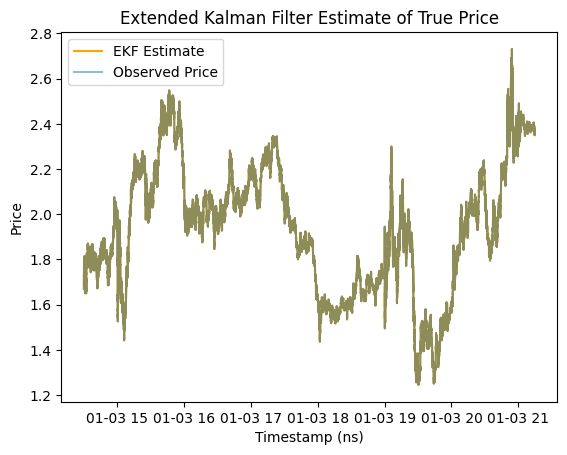

In [35]:
plt.plot(
    df_quotes_result["ts_ns"],
    df_quotes_result["kalman_price"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_quotes_result["ts_ns"], df_quotes_result["observed_price"], label="Observed Price", alpha=0.5
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

In [36]:
df_trades_result

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,kalman_prior,trade_residual
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64
2024-01-03 09:30:00.424 EST,"""trade""",1.67,0.02,1.7,1.72,54.0,40.0,0.000025,149615872,1.75875,-0.08875
2024-01-03 09:30:00.472 EST,"""trade""",1.69,0.02,1.7,1.72,54.0,40.0,0.000025,101615872,1.750479,-0.060479
2024-01-03 09:30:00.576 EST,"""trade""",1.7,0.02,1.7,1.72,40.0,40.0,0.000025,213349376,1.711489,-0.011489
2024-01-03 09:30:00.617 EST,"""trade""",1.71,0.02,1.7,1.72,40.0,40.0,0.000025,172349376,1.711489,-0.001489
2024-01-03 09:30:01.480 EST,"""trade""",1.71,0.02,1.7,1.72,54.0,40.0,0.000025,-460488192,1.711491,-0.001491
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,27.0,37.0,0.000006,-107716608,2.394219,-0.024219
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,27.0,37.0,0.000006,-107716608,2.394219,-0.024219
2024-01-03 16:12:51.108 EST,"""trade""",2.38,0.03,2.36,2.39,85.0,110.0,0.000056,-8484553728,2.373077,0.006923


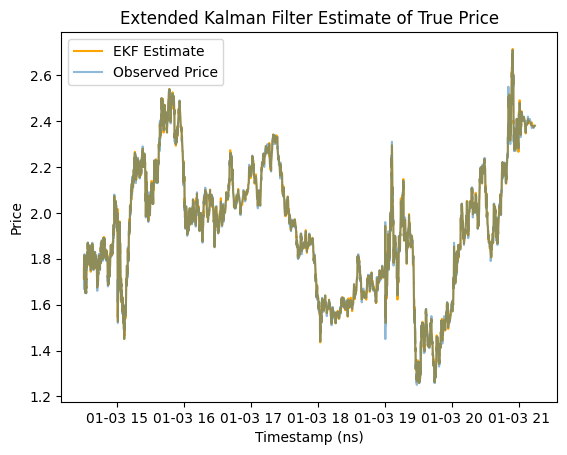

In [37]:
plt.plot(
    df_trades_result["ts_ns"],
    df_trades_result["kalman_prior"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_trades_result["ts_ns"], df_trades_result["observed_price"], label="Observed Price", alpha=0.5
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

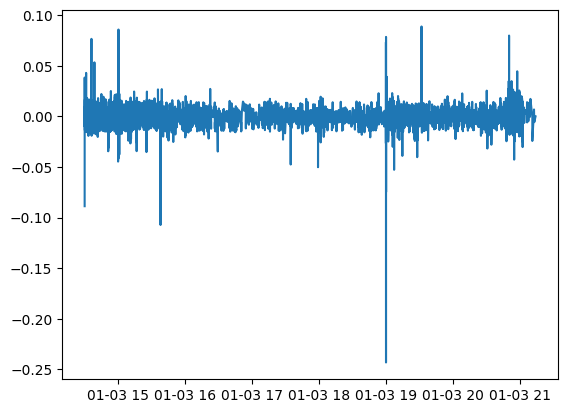

In [38]:
plt.plot(df_trades_result["ts_ns"], df_trades_result["trade_residual"])

In [39]:
df_trades_result.select((pl.col("trade_residual") ** 2).mean())

trade_residual
f64
0.000092


Filter using the laggeddness

In [40]:
df_trades_result

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,kalman_prior,trade_residual
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64
2024-01-03 09:30:00.424 EST,"""trade""",1.67,0.02,1.7,1.72,54.0,40.0,0.000025,149615872,1.75875,-0.08875
2024-01-03 09:30:00.472 EST,"""trade""",1.69,0.02,1.7,1.72,54.0,40.0,0.000025,101615872,1.750479,-0.060479
2024-01-03 09:30:00.576 EST,"""trade""",1.7,0.02,1.7,1.72,40.0,40.0,0.000025,213349376,1.711489,-0.011489
2024-01-03 09:30:00.617 EST,"""trade""",1.71,0.02,1.7,1.72,40.0,40.0,0.000025,172349376,1.711489,-0.001489
2024-01-03 09:30:01.480 EST,"""trade""",1.71,0.02,1.7,1.72,54.0,40.0,0.000025,-460488192,1.711491,-0.001491
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,27.0,37.0,0.000006,-107716608,2.394219,-0.024219
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,27.0,37.0,0.000006,-107716608,2.394219,-0.024219
2024-01-03 16:12:51.108 EST,"""trade""",2.38,0.03,2.36,2.39,85.0,110.0,0.000056,-8484553728,2.373077,0.006923


In [41]:
# check the raw lag values first
print(df_trades_result["matched_lag_ns"].describe())
print(df_trades_result["matched_lag_ns"].head(20))

shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 8895.0       │
│ null_count ┆ 0.0          │
│ mean       ┆ -2.4414e8    │
│ std        ┆ 8.9209e8     │
│ min        ┆ -2.0605e10   │
│ 25%        ┆ -2.7188e8    │
│ 50%        ┆ 2.2292544e7  │
│ 75%        ┆ 1.5990528e8  │
│ max        ┆ 2.49958208e8 │
└────────────┴──────────────┘
shape: (20,)
Series: 'matched_lag_ns' [i64]
[
	149615872
	101615872
	213349376
	172349376
	-460488192
	…
	121194176
	-233099264
	-54716672
	-181716672
	-206716672
]


In [42]:
(df_trades_result["matched_lag_ns"] > 0).sum()

5037

In [43]:
df_trades_result["matched_lag_ns"].hist(include_breakpoint=True)

breakpoint,category,count
f64,cat,u32
-1.8519e10,"""[-2.0605e10, -1.8519e10]""",1
-1.6434e10,"""(-1.8519e10, -1.6434e10]""",0
-1.4348e10,"""(-1.6434e10, -1.4348e10]""",0
-1.2263e10,"""(-1.4348e10, -1.2263e10]""",5
-1.0177e10,"""(-1.2263e10, -1.0177e10]""",0
-8.0918e9,"""(-1.0177e10, -8.0918e9]""",1
-6.0064e9,"""(-8.0918e9, -6.0064e9]""",35
-3.9209e9,"""(-6.0064e9, -3.9209e9]""",43
-1.8355e9,"""(-3.9209e9, -1.8355e9]""",282


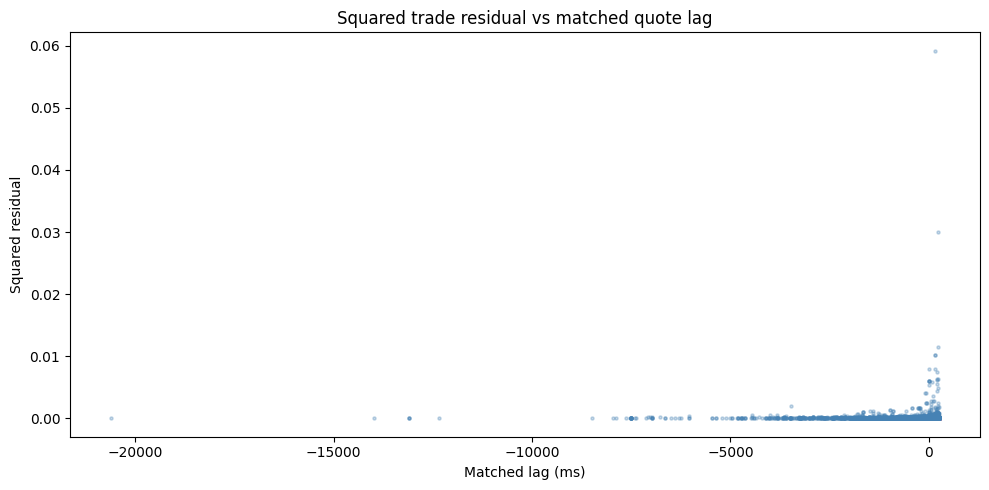

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    df_trades_result["matched_lag_ns"].to_numpy() / 1_000_000,
    df_trades_result["trade_residual"].pow(2).to_numpy(),
    alpha=0.3,
    s=5,
    color="steelblue",
)
ax.set_xlabel("Matched lag (ms)")
ax.set_ylabel("Squared residual")
ax.set_title("Squared trade residual vs matched quote lag")
plt.tight_layout()
plt.show()

In [48]:
df_plot = df_trades_result.with_columns(
    [
        (df_trades_result["trade_residual"] ** 2).alias("squared_residual"),
        pl.when(pl.col("matched_lag_ns") >= 0)
        .then(pl.lit("forward (≤250ms)"))
        .otherwise(pl.lit("backward fallback"))
        .alias("match_type"),
    ]
)

fig = px.scatter(
    df_plot.to_pandas(),
    x="matched_lag_ns",
    y="squared_residual",
    color="match_type",
    labels={"matched_lag_ns": "Matched lag (ms)", "squared_residual": "Squared residual"},
    title="Squared trade residual vs matched quote lag",
    opacity=0.3,
    color_discrete_map={"forward (≤250ms)": "steelblue", "backward fallback": "tomato"},
)
fig.update_traces(marker=dict(size=3))
fig.show()

In [ ]:
df_trades_result

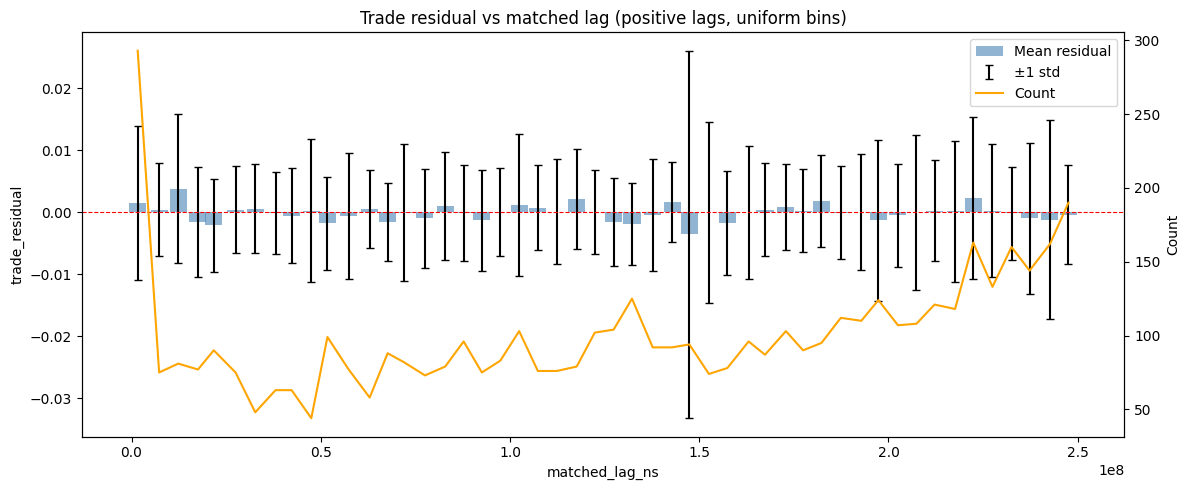

In [51]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

# Filter positive lag only
df = df_trades_result.filter(pl.col("matched_lag_ns") > 0)

# Define uniform bins
n_bins = 50
lag_min = df["matched_lag_ns"].min()
lag_max = df["matched_lag_ns"].max()
bins = np.linspace(lag_min, lag_max, n_bins + 1)

# Assign bin index
df = df.with_columns(pl.col("matched_lag_ns").cut(breaks=bins[1:-1].tolist()).alias("bin"))

grouped = (
    df.group_by("bin", maintain_order=False)
    .agg(
        [
            pl.col("trade_residual").mean().alias("mean"),
            pl.col("trade_residual").std().alias("std"),
            pl.col("matched_lag_ns").mean().alias("bin_center"),
            pl.col("trade_residual").count().alias("count"),
        ]
    )
    .sort("bin_center")
)

bin_centers = grouped["bin_center"].to_numpy()
means = grouped["mean"].to_numpy()
stds = grouped["std"].to_numpy()
counts = grouped["count"].to_numpy()

fig, ax1 = plt.subplots(figsize=(12, 5))
bar_width = (bins[1] - bins[0]) * 0.9

ax1.bar(bin_centers, means, width=bar_width, alpha=0.6, label="Mean residual", color="steelblue")
ax1.errorbar(bin_centers, means, yerr=stds, fmt="none", color="black", capsize=3, label="±1 std")
ax1.axhline(0, color="red", linestyle="--", linewidth=0.8)
ax1.set_xlabel("matched_lag_ns")
ax1.set_ylabel("trade_residual")

ax2 = ax1.twinx()
ax2.plot(bin_centers, counts, color="orange", linewidth=1.5, label="Count")
ax2.set_ylabel("Count")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title("Trade residual vs matched lag (positive lags, uniform bins)")
plt.tight_layout()
plt.show()

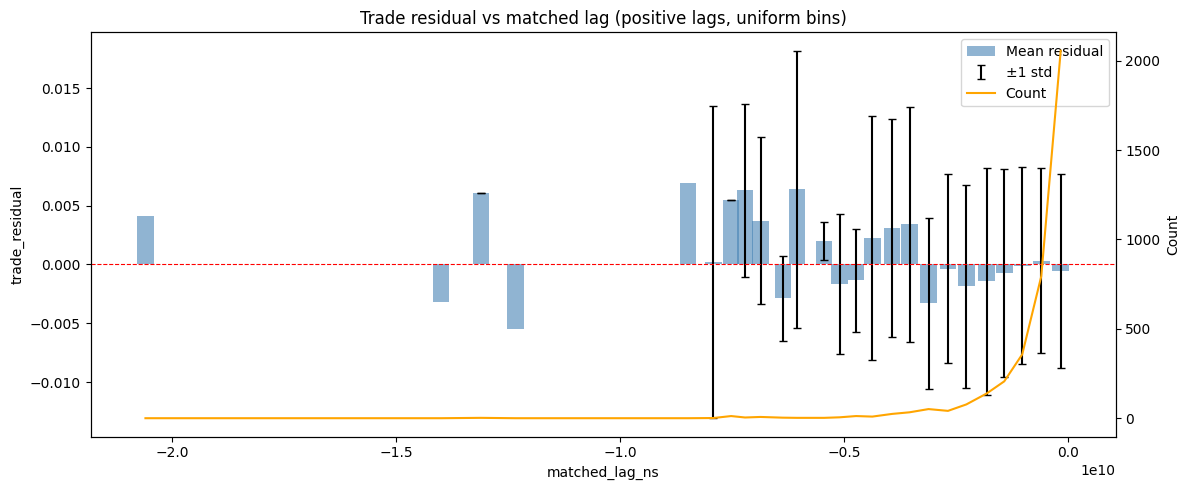

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

# Filter positive lag only
df = df_trades_result.filter(pl.col("matched_lag_ns") < 0)

# Define uniform bins
n_bins = 50
lag_min = df["matched_lag_ns"].min()
lag_max = df["matched_lag_ns"].max()
bins = np.linspace(lag_min, lag_max, n_bins + 1)

# Assign bin index
df = df.with_columns(pl.col("matched_lag_ns").cut(breaks=bins[1:-1].tolist()).alias("bin"))

grouped = (
    df.group_by("bin", maintain_order=False)
    .agg(
        [
            pl.col("trade_residual").mean().alias("mean"),
            pl.col("trade_residual").std().alias("std"),
            pl.col("matched_lag_ns").mean().alias("bin_center"),
            pl.col("trade_residual").count().alias("count"),
        ]
    )
    .sort("bin_center")
)

bin_centers = grouped["bin_center"].to_numpy()
means = grouped["mean"].to_numpy()
stds = grouped["std"].to_numpy()
counts = grouped["count"].to_numpy()

fig, ax1 = plt.subplots(figsize=(12, 5))
bar_width = (bins[1] - bins[0]) * 0.9

ax1.bar(bin_centers, means, width=bar_width, alpha=0.6, label="Mean residual", color="steelblue")
ax1.errorbar(bin_centers, means, yerr=stds, fmt="none", color="black", capsize=3, label="±1 std")
ax1.axhline(0, color="red", linestyle="--", linewidth=0.8)
ax1.set_xlabel("matched_lag_ns")
ax1.set_ylabel("trade_residual")

ax2 = ax1.twinx()
ax2.plot(bin_centers, counts, color="orange", linewidth=1.5, label="Count")
ax2.set_ylabel("Count")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title("Trade residual vs matched lag (positive lags, uniform bins)")
plt.tight_layout()
plt.show()

In [53]:
import plotly.express as px

fig = px.scatter(
    x=df_trades_result["matched_lag_ns"].to_numpy() / 1_000_000,
    y=df_trades_result["trade_residual"].to_numpy() ** 2,
    labels={"x": "Matched lag (ms)", "y": "Squared residual"},
    title="Squared trade residual vs matched quote lag",
    opacity=0.3,
)
fig.update_traces(marker=dict(size=3))
fig.show()

## NOW IMPLIED VOL

In [54]:
df_spy

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.003119872 EST,470.43,100.0,0
2024-01-03 09:30:00.021508608 EST,470.46,100.0,0
2024-01-03 09:30:00.021577984 EST,470.46,100.0,0
2024-01-03 09:30:00.033044224 EST,470.4301,741.0,0
2024-01-03 09:30:00.035522560 EST,470.46,100.0,0
…,…,…,…
2024-01-03 16:00:00.050740480 EST,468.74,300.0,0
2024-01-03 16:00:00.050803456 EST,468.74,400.0,0
2024-01-03 16:00:00.050809600 EST,468.74,100.0,0


In [55]:
df_events = df_events.join_asof(
    df_spy.select(["ts_ns", "price"]), on="ts_ns", strategy="backward"
).rename({"price": "spot"})

In [56]:
# import jax.numpy as jnp
# from jax.scipy.special import ndtr  # fast normal CDF


# def bs_call_price(S, K, T, r, sigma):
#     sqrtT = jnp.sqrt(T)
#     d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
#     d2 = d1 - sigma * sqrtT
#     return S * ndtr(d1) - K * jnp.exp(-r * T) * ndtr(d2)


# def bs_vega(S, K, T, r, sigma):
#     sqrtT = jnp.sqrt(T)
#     d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
#     pdf = jnp.exp(-0.5 * d1**2) / jnp.sqrt(2 * jnp.pi)
#     return S * sqrtT * pdf


# @jax.jit
# def implied_vol_batch(price, S, K, T, r, n_iter=20):
#     sigma = jnp.full_like(price, 0.2)

#     def step(_, sigma):
#         model = bs_call_price(S, K, T, r, sigma)
#         vega = bs_vega(S, K, T, r, sigma)
#         sigma = sigma - (model - price) / jnp.maximum(vega, 1e-8)
#         return jnp.clip(sigma, 1e-4, 5.0)

#     sigma = jax.lax.fori_loop(0, n_iter, step, sigma)
#     return sigma

In [57]:
from functools import partial

import jax
import jax.numpy as jnp
import polars as pl


# --- Black-Scholes price & vega ---
@jax.jit
def bs_call_price(S, K, T, r, sigma):
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * jnp.sqrt(T))
    d2 = d1 - sigma * jnp.sqrt(T)
    norm = jax.scipy.stats.norm
    return S * norm.cdf(d1) - K * jnp.exp(-r * T) * norm.cdf(d2)


@jax.jit
def bs_vega(S, K, T, r, sigma):
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * jnp.sqrt(T))
    return S * jax.scipy.stats.norm.pdf(d1) * jnp.sqrt(T)


# --- Single Newton-Raphson step ---
@jax.jit
def newton_iv(market_price, S, K, T, r, max_iter=10):
    sigma = jnp.full_like(market_price, 0.3)  # initial guess

    def step(sigma, _):
        price = bs_call_price(S, K, T, r, sigma)
        vega = bs_vega(S, K, T, r, sigma)
        # Clip vega to avoid div-by-zero
        return sigma - (price - market_price) / jnp.where(vega < 1e-8, 1e-8, vega), None

    sigma, _ = jax.lax.scan(step, sigma, None, length=max_iter)
    return sigma

In [58]:
df_events.select(pl.col("ts_ns"))

ts_ns
"datetime[ns, America/New_York]"
2024-01-03 09:30:00.183667200 EST
2024-01-03 09:30:00.217322240 EST
2024-01-03 09:30:00.383298048 EST
2024-01-03 09:30:00.400694528 EST
2024-01-03 09:30:00.419033088 EST
…
2024-01-03 16:14:42.406433024 EST
2024-01-03 16:14:42.450262016 EST
2024-01-03 16:14:54.333178624 EST


In [59]:
# Expiry: next day at 16:00 ET (standard US equity options close)
expiry = datetime(2024, 1, 4, 16, 0, 0, tzinfo=pytz.timezone("America/New_York"))

df_events = df_events.with_columns(
    [
        (
            (pl.lit(expiry) - pl.col("ts_ns")).dt.total_nanoseconds() / (365.25 * 24 * 3600 * 1e9)
        ).alias("T")
    ]
)

In [60]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,spot,T
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.45,0.003479
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,0,470.45,0.003479
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.46,0.003479
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,0,470.46,0.003479
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,0,470.46,0.003479
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,0,468.74,0.00271
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,0,468.74,0.00271
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,0,468.74,0.00271


In [61]:
# Extract as JAX arrays (zero-copy via numpy)
price = jnp.array(df_events["observed_price"].to_numpy())
S = jnp.array(df_events["spot"].to_numpy())
K = jnp.full_like(price, 470.0)  # hardcoded strike for this contract
T = jnp.array(df_events["T"].to_numpy())  # time to expiry in years
r = jnp.full_like(price, 0.0)  # assume 0 for intraday changes

iv = newton_iv(price, S, K, T, r)

# Write back
df_events = df_events.with_columns(pl.Series("iv", iv.tolist()))

In [62]:
bid_price = jnp.array(df_events["bid_price"].to_numpy())
ask_price = jnp.array(df_events["ask_price"].to_numpy())
bid_iv = newton_iv(bid_price, S, K, T, r)
ask_iv = newton_iv(ask_price, S, K, T, r)
df_events = df_events.with_columns(
    [
        pl.Series("bid_iv", bid_iv.tolist()),
        pl.Series("ask_iv", ask_iv.tolist()),
    ]
)

In [63]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,spot,T,iv,bid_iv,ask_iv
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.45,0.003479,0.135038,0.133215,0.136859
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,0,470.45,0.003479,0.135038,0.134127,0.135948
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.46,0.003479,0.134535,0.132715,0.136359
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,0,470.46,0.003479,0.131422,0.130897,0.140908
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,0,470.46,0.003479,0.137236,0.129072,0.140908
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,0,468.74,0.00271,0.301807,0.301316,0.303399
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,0,468.74,0.00271,0.301952,0.301314,0.303398
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,0,468.74,0.00271,0.303834,0.302378,0.30446


In [64]:
df_events = df_events.with_columns(
    (
        pl.col("R")
        * (((pl.col("ask_iv") - pl.col("bid_iv")) / 2) ** 2)
        / ((pl.col("spread") / 2) ** 2)
    ).alias("R_iv")
)

In [65]:
df_events = df_events.rename({"iv": "observed_iv"})

In [66]:
df_events = df_events.with_columns(
    ((((pl.col("ask_iv") - pl.col("bid_iv")) * 100) / 2) ** 2).alias("R_iv")
).with_columns(
    pl.when(pl.col("event_type") == "trade")
    .then(pl.col("R_iv").fill_null(strategy="forward") / TRADE_R_DIVISOR)
    .otherwise(pl.col("R_iv"))
    .alias("R_iv")
)

In [67]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,spot,T,observed_iv,bid_iv,ask_iv,R_iv
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.45,0.003479,0.135038,0.133215,0.136859,0.03319
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,0,470.45,0.003479,0.135038,0.134127,0.135948,0.008293
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.46,0.003479,0.134535,0.132715,0.136359,0.033199
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,0,470.46,0.003479,0.131422,0.130897,0.140908,0.250582
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,0,470.46,0.003479,0.137236,0.129072,0.140908,0.350229
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,0,468.74,0.00271,0.301807,0.301316,0.303399,0.010855
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,0,468.74,0.00271,0.301952,0.301314,0.303398,0.010853
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,0,468.74,0.00271,0.303834,0.302378,0.30446,0.010847


## KF on IV

In [68]:
def f(x):
    return x


def h(x):
    return x


def ekf_step(x, P, z, R_scalar, Q):
    F = jax.jacrev(f)(x)
    x_pred = f(x)
    P_pred = F @ P @ F.T + Q

    H = jax.jacrev(h)(x_pred)
    y = z - h(x_pred)
    S = H @ P_pred @ H.T + R_scalar
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    x_new = x_pred + K @ y
    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred
    return x_new, P_new


@jax.jit
def run_ekf(prices, Rs):
    x0 = jnp.array([prices[0]], dtype=jnp.float32)
    P0 = jnp.array([[1.0]], dtype=jnp.float32)
    Q = jnp.array([[0.01]], dtype=jnp.float32)

    def scan_step(carry, obs):
        x, P = carry
        price, R_scalar = obs
        z = jnp.array([price], dtype=jnp.float32)
        R = jnp.array([[R_scalar]], dtype=jnp.float32)
        x_new, P_new = ekf_step(x, P, z, R, Q)
        return (x_new, P_new), x_new[0]

    (_, _), estimates = jax.lax.scan(scan_step, (x0, P0), (prices, Rs))
    return estimates


def estimate_true_iv(df_events: pl.DataFrame) -> pl.DataFrame:
    prices = jnp.array(df_events["observed_iv"].to_numpy(), dtype=jnp.float32)
    Rs = jnp.array(df_events["R_iv"].to_numpy(), dtype=jnp.float32)

    estimates = run_ekf(prices, Rs)

    return df_events.with_columns(
        pl.Series(name="kalman_iv", values=jax.device_get(estimates).tolist())
    )


# Usage
# df_result = estimate_true_iv(df_events)

In [69]:
# ── STEP 1: Train the Kalman filter on quotes only ───────────────────────────
df_iv_quotes_only = df_events.filter(pl.col("event_type") == "quote")

prices_train = jnp.array(df_iv_quotes_only["observed_price"].to_numpy(), dtype=jnp.float32)
Rs_train = jnp.array(df_iv_quotes_only["R"].to_numpy(), dtype=jnp.float32)

estimates_train = run_ekf(prices_train, Rs_train)

df_iv_quotes_result = df_iv_quotes_only.with_columns(
    pl.Series("kalman_price", jax.device_get(estimates_train).tolist())
)

# ── STEP 2: Test on trades ────────────────────────────────────────────────────
# For each trade, get the Kalman estimate from the most recent preceding quote.
# This is a pure out-of-sample evaluation: the filter never saw trades.

df_iv_trades_only = df_events.filter(pl.col("event_type") == "trade")

df_iv_trades_result = df_iv_trades_only.join_asof(
    df_iv_quotes_result.select(["ts_ns", "kalman_price"]).rename({"kalman_price": "kalman_prior"}),
    on="ts_ns",
    strategy="backward",
)

# Residual: how far is the trade price from the filter's quote-derived estimate?
df_iv_trades_result = df_iv_trades_result.with_columns(
    (pl.col("observed_price") - pl.col("kalman_prior")).alias("trade_residual")
)

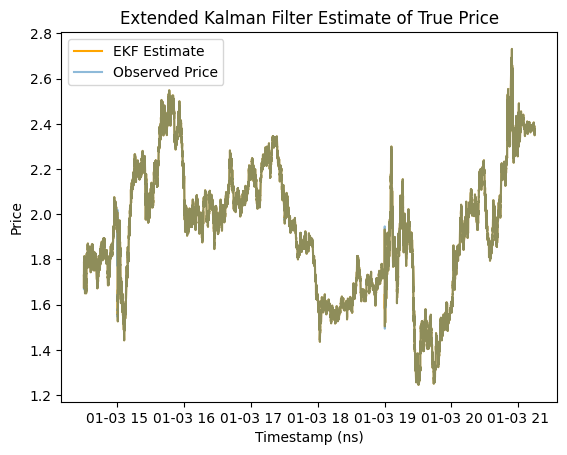

In [70]:
plt.plot(
    df_iv_quotes_result["ts_ns"],
    df_iv_quotes_result["kalman_price"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_iv_quotes_result["ts_ns"],
    df_iv_quotes_result["observed_price"],
    label="Observed Price",
    alpha=0.5,
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

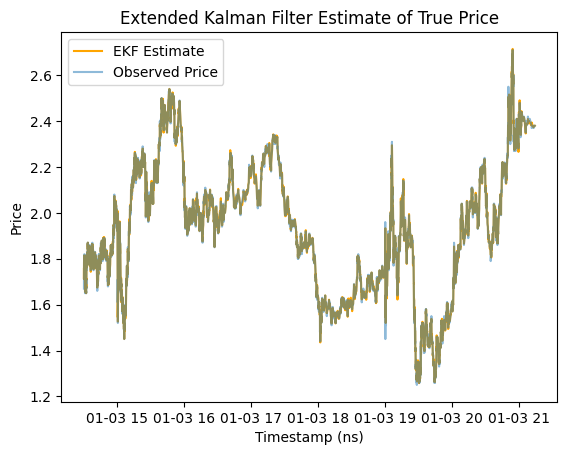

In [71]:
plt.plot(
    df_iv_trades_result["ts_ns"],
    df_iv_trades_result["kalman_prior"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_iv_trades_result["ts_ns"],
    df_iv_trades_result["observed_price"],
    label="Observed Price",
    alpha=0.5,
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

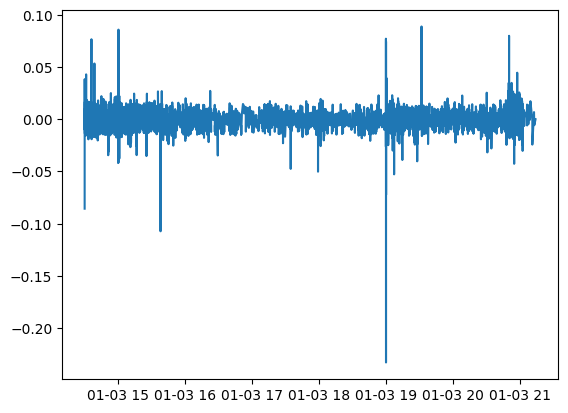

In [72]:
plt.plot(df_iv_trades_result["ts_ns"], df_iv_trades_result["trade_residual"])

In [80]:
df_iv_trades_result.select((pl.col("trade_residual") ** 2).mean()) * 10000

trade_residual
f64
0.906297


comparison

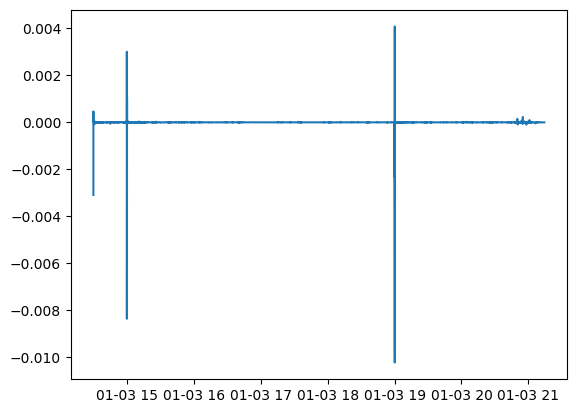

In [74]:
plt.plot(
    df_trades_result["ts_ns"],
    df_trades_result["trade_residual"] - df_iv_trades_result["trade_residual"],
)

In [75]:
diff = df_trades_result["trade_residual"] - df_iv_trades_result["trade_residual"]

In [76]:
diff.abs().mean()

1.6910377146488765e-05

In [77]:
diff.abs().max()

0.010219693183898926

In [78]:
diff.shape

(8895,)

In [79]:
(diff.abs() > 0.0001).sum()

62